In [1]:
import requests, pandas as pd
H = {"User-Agent": "Mozilla/5.0 (research data download; contact via Kaggle)"}
base = "https://dataverse.harvard.edu/api/datasets/:persistentId/versions/{v}/files?persistentId=doi:10.7910/DVN/VEADSE"
for v in [":latest-published", ":latest"]:
    r = requests.get(base.format(v=v), headers=H, timeout=60)
    print(v, "->", r.status_code)
    if r.ok:
        files = pd.DataFrame([{"name": f["dataFile"]["filename"], "MB": round(f["dataFile"]["filesize"] / 1e6, 1),
                               "id": f["dataFile"]["id"],
                               "restricted": f.get("restricted", False)} for f in r.json()["data"]])
        print(files.to_string(index=False)); print("\nTotal:", round(files.MB.sum() / 1000, 2), "GB")
        break
    print("Server says:", r.text[:400], "\n")

:latest-published -> 200
                                     name     MB       id  restricted
 DATASHEET_FOR_MALARIA_DATASETS-GHANA.pdf    0.1  7225282       False
DATASHEET_FOR_MALARIA_DATASETS-UGANDA.pdf    0.1  7225281       False
                    Thick_Ghana.part1.rar 2147.5 10428487       False
                    Thick_Ghana.part2.rar 2147.5 10428486       False
                    Thick_Ghana.part3.rar  695.4 10428485       False
                    Thin_Images_Ghana.rar 1513.5 10428456       False
                          Thin_Uganda.rar  729.8 10428455       False

Total: 7.23 GB


In [2]:
!which unrar 7z unar || echo "--- none found yet ---"
!apt-get install -y -qq unar > /dev/null 2>&1 && echo "unar installed" || echo "unar install failed"
!unar -v | head -1

/usr/bin/unrar
/usr/bin/7z
--- none found yet ---
unar install failed
/bin/bash: line 1: unar: command not found


In [3]:
!pip install -q pypdf
from pypdf import PdfReader
import os
os.makedirs("/tmp/gh", exist_ok=True)
pdf = "/tmp/gh/datasheet_ghana.pdf"
r = requests.get("https://dataverse.harvard.edu/api/access/datafile/7225282", headers=H, timeout=120)
open(pdf, "wb").write(r.content)
text = "\n".join(p.extract_text() or "" for p in PdfReader(pdf).pages)
print(len(text), "characters\n")
print(text[:6000])

8226 characters

Data
Sheet
for
Malaria
Image
Data
Collected
in
Ghana
Under
the
Lacuna
Project
We
present
the
Lacuna
Malaria
data
sheet
created
by
MinoHealth
AI
Labs.
We
follow
the
datasheet
for
the
dataset
framework
created
by
(Gebru
et
al.
2021).
Motivation
For
what
purpose
was
the
data
set
created?
Was
there
a
specific
task
in
mind?
The
dataset
was
created
with
the
specific
purpose
of
advancing
research
and
development
in
the
field
of
malaria
diagnosis
and
detection.
By
collecting
the
dataset
from
Ghana,
a
diverse
and
well-annotated
collection
of
malaria
thin
and
thick
blood
smear
images
will
be
made
available
to
support
the
development
of
accurate,
efficient,
and
scalable
methods
for
malaria
diagnosis.
Who
created
this
data
set
(e.g.
which
team,
research
group)
and
on
behalf
of
which
entity
(e.g.
company,
institution,
organization)?
The
dataset
was
created
by
a
team
of
data
scientists
from
the
minoHealth
AI
Labs,
with
support
from
medical
officers,
medical
laboratory
scientists
and

In [4]:
UA = H["User-Agent"]
for fid, name in [(10428487, "Thick_Ghana.part1.rar"), (10428486, "Thick_Ghana.part2.rar"), (10428485, "Thick_Ghana.part3.rar")]:
    !wget -q --show-progress --user-agent="{UA}" "https://dataverse.harvard.edu/api/access/datafile/{fid}" -O /tmp/gh/{name}
!ls -la /tmp/gh
!cd /tmp/gh && unrar x -o+ -inul Thick_Ghana.part1.rar /tmp/gh/data/ && echo "unpacked OK"
!rm -f /tmp/gh/*.rar
!du -sh /tmp/gh/data && find /tmp/gh/data -maxdepth 3 -type d | head -20

/tmp/gh/Thick_Ghana 100%[===================>]   2.00G  87.4MB/s    in 22s     
/tmp/gh/Thick_Ghana 100%[===================>]   2.00G  71.1MB/s    in 28s     
/tmp/gh/Thick_Ghana 100%[===================>] 663.16M  59.2MB/s    in 10s     
total 4873524
drwxr-xr-x 2 root root       4096 Oct 20 23:57 .
drwxrwxrwt 1 root root       4096 Oct 20 23:56 ..
-rw-r--r-- 1 root root     126417 Oct 20 23:56 datasheet_ghana.pdf
-rw-r--r-- 1 root root 2147483648 Feb 18  2026 Thick_Ghana.part1.rar
-rw-r--r-- 1 root root 2147483648 Feb 18  2026 Thick_Ghana.part2.rar
-rw-r--r-- 1 root root  695375448 Feb 18  2026 Thick_Ghana.part3.rar
unpacked OK
4.9G	/tmp/gh/data
/tmp/gh/data
/tmp/gh/data/Ghana
/tmp/gh/data/Ghana/Thick
/tmp/gh/data/Ghana/Thick/images
/tmp/gh/data/Ghana/Thick/labels_yolo


In [5]:
!du -sh /tmp/gh/data
!find /tmp/gh/data -maxdepth 3 -type d | head -20
!find /tmp/gh/data -type f | sed 's/.*\.//' | sort | uniq -c
print("\n--- DATASHEET ---\n")
print(" ".join(text.split())[:7000])

4.9G	/tmp/gh/data
/tmp/gh/data
/tmp/gh/data/Ghana
/tmp/gh/data/Ghana/Thick
/tmp/gh/data/Ghana/Thick/images
/tmp/gh/data/Ghana/Thick/labels_yolo
   3045 jpg
   3045 txt

--- DATASHEET ---

Data Sheet for Malaria Image Data Collected in Ghana Under the Lacuna Project We present the Lacuna Malaria data sheet created by MinoHealth AI Labs. We follow the datasheet for the dataset framework created by (Gebru et al. 2021). Motivation For what purpose was the data set created? Was there a specific task in mind? The dataset was created with the specific purpose of advancing research and development in the field of malaria diagnosis and detection. By collecting the dataset from Ghana, a diverse and well-annotated collection of malaria thin and thick blood smear images will be made available to support the development of accurate, efficient, and scalable methods for malaria diagnosis. Who created this data set (e.g. which team, research group) and on behalf of which entity (e.g. company, institut

In [6]:
from pathlib import Path
from collections import Counter
import pandas as pd, numpy as np
from PIL import Image

G = Path("/tmp/gh/data/Ghana/Thick")
imgs = sorted((G / "images").glob("*.jpg"))
print("Sample names:", [p.name for p in imgs[:4]])

sizes, flags = Counter(), Counter()
for p in imgs:
    im = Image.open(p); sizes[im.size] += 1; flags[im.getexif().get(274, 1)] += 1
print("Image sizes:", sizes.most_common(5)); print("Rotate flags:", dict(flags))

rows = []
for p in imgs:
    t = G / "labels_yolo" / f"{p.stem}.txt"
    for line in (t.read_text().strip().splitlines() if t.exists() else []):
        v = line.split()
        if len(v) >= 5: rows.append((p.stem, int(float(v[0])), *map(float, v[1:5])))
lab = pd.DataFrame(rows, columns=["image", "cls", "xc", "yc", "w", "h"])
print("\nLabels:", len(lab)); print(lab.cls.value_counts())
print("Images with no labels:", len(imgs) - lab.image.nunique(), "of", len(imgs))
print("\nMedian box size (as a fraction of the image) per class:\n", lab.groupby("cls")[["w", "h"]].median().round(4))

Sample names: ['0.jpg', '1.jpg', '10.jpg', '100.jpg']
Image sizes: [((4096, 3072), 2656), ((2976, 2976), 271), ((1600, 1200), 7), ((1803, 1820), 1), ((1880, 1697), 1)]
Rotate flags: {1: 600, 6: 2434, 3: 11}

Labels: 377166
cls
0    360900
1     16266
Name: count, dtype: int64
Images with no labels: 2 of 3045

Median box size (as a fraction of the image) per class:
           w       h
cls                
0    0.0156  0.0132
1    0.0460  0.0375


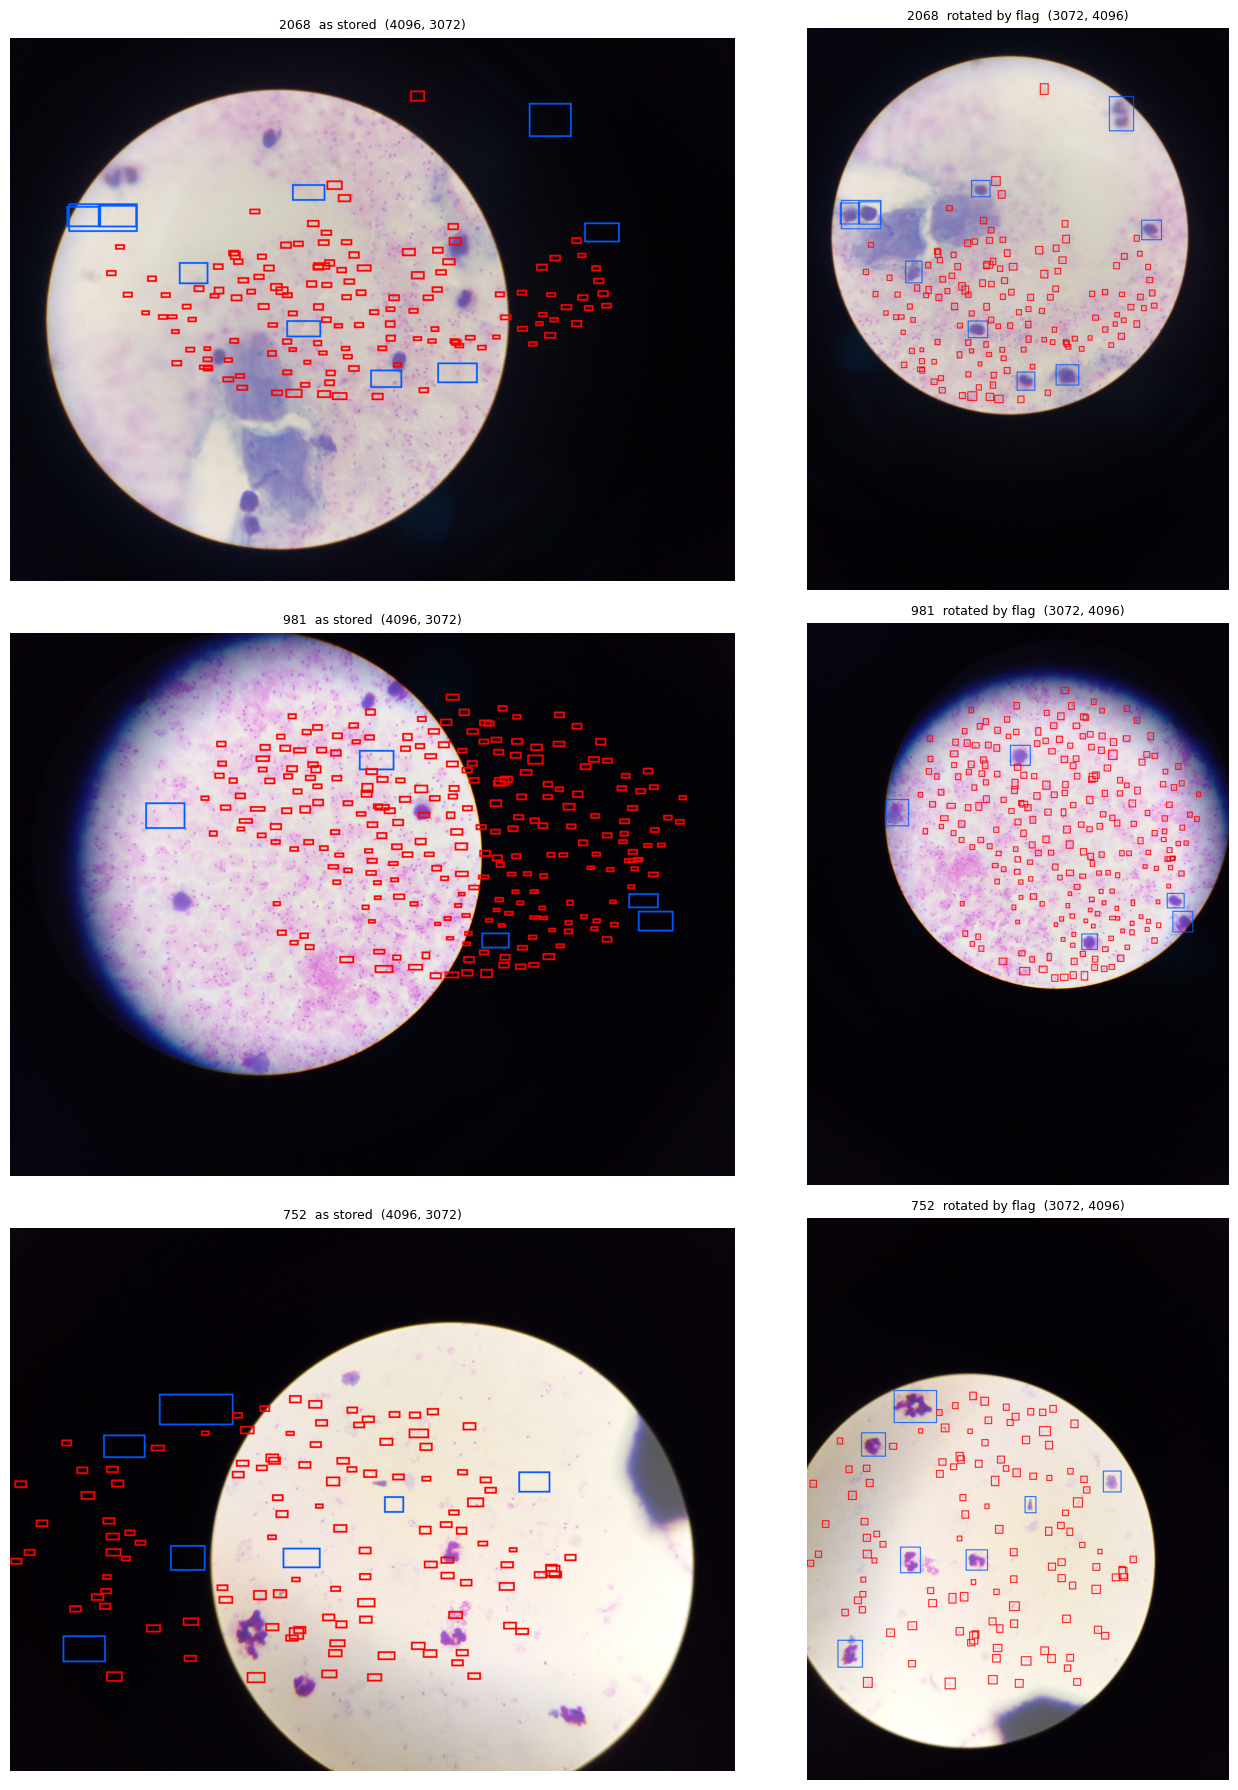

In [7]:
import random, matplotlib.pyplot as plt
from PIL import ImageOps, ImageDraw
rot = [p for p in imgs if Image.open(p).getexif().get(274, 1) != 1]
random.seed(3); pick = random.sample(rot if len(rot) >= 3 else imgs, 3)

fig, axes = plt.subplots(3, 2, figsize=(14, 18))
for row, p in enumerate(pick):
    a = lab[lab.image == p.stem]
    versions = [("as stored", Image.open(p).convert("RGB")),
                ("rotated by flag", ImageOps.exif_transpose(Image.open(p)).convert("RGB"))]
    for col, (title, im) in enumerate(versions):
        W, H = im.size; d = ImageDraw.Draw(im)
        for _, o in a.iterrows():
            box = [(o.xc - o.w/2) * W, (o.yc - o.h/2) * H, (o.xc + o.w/2) * W, (o.yc + o.h/2) * H]
            d.rectangle(box, outline=[(255, 0, 0), (0, 90, 255), (0, 200, 0)][o.cls % 3], width=max(3, W // 400))
        axes[row, col].imshow(im); axes[row, col].set_title(f"{p.stem[:25]}  {title}  {im.size}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

In [8]:
from PIL import ImageOps
flag = {p.stem: Image.open(p).getexif().get(274, 1) for p in imgs}
size = {p.stem: Image.open(p).size for p in imgs}
disp = {k: (s[1], s[0]) if flag[k] in (5, 6, 7, 8) else s for k, s in size.items()}   

lab["W"] = lab.image.map(lambda k: disp[k][0]); lab["H"] = lab.image.map(lambda k: disp[k][1])
lab["box_px"] = (lab.w * lab.W + lab.h * lab.H) / 2
lab["group"] = lab.W.astype(str) + "x" + lab.H.astype(str)

g = lab.groupby(["group", "cls"]).box_px.median().unstack()
g.columns = ["parasite_px", "wbc_px"]
g["scale"] = 24.8 / g.parasite_px               
g["wbc_after_scaling"] = g.wbc_px * g.scale
g["images"] = lab.groupby("group").image.nunique()
print(g.round(3))

per_img = lab.groupby(["image", "cls"]).size().unstack(fill_value=0); per_img.columns = ["parasite", "wbc"]
print("\n", per_img.describe().round(1))
print("Images with zero WBCs:", (per_img.wbc == 0).sum())
print("Pooled parasites per WBC:", round(per_img.parasite.sum() / per_img.wbc.sum(), 2))

           parasite_px   wbc_px  scale  wbc_after_scaling  images
group                                                            
1162x1427       39.303      NaN  0.631                NaN       1
1200x1600       24.854   58.562  0.998             58.435       7
1226x1288       37.694      NaN  0.658                NaN       1
1256x2727       50.765      NaN  0.489                NaN       1
1354x1992       44.796  139.276  0.554             77.105       1
...                ...      ...    ...                ...     ...
3072x1518       41.542  122.181  0.597             72.940       1
3072x1641       42.737  144.000  0.580             83.563       1
3072x2426       44.655  166.667  0.555             92.561       1
3072x4096       49.486  144.823  0.501             72.579    2243
4096x3072       48.045  143.857  0.516             74.257     411

[115 rows x 5 columns]

        parasite     wbc
count    3043.0  3043.0
mean      118.6     5.3
std        84.2     5.4
min         0.0     

In [9]:
import yaml
OUT = Path("/kaggle/working/gh_images")
for sub in ["images", "labels"]:
    (OUT / "test" / sub).mkdir(parents=True, exist_ok=True)
main = g.loc[["3072x4096", "4096x3072"], "scale"].mean()                   
scale_of = {k: (r.scale if r.images >= 5 else main) for k, r in g.iterrows()}
own = g[g.images >= 5]
print("Groups with their own scale:\n", own[["images", "scale"]].round(3))
print("Images using the main-phone scale:", int(g[g.images < 5].images.sum()), "| main scale:", round(main, 3))
grp = lab.drop_duplicates("image").set_index("image").group.to_dict()

done = 0
for p in imgs:
    if p.stem not in grp: continue                                  
    im = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      
    s = scale_of[grp[p.stem]]
    im = im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR)
    im.save(OUT / "test" / "images" / f"gh_{p.stem}.jpg", quality=92) 
    a = lab[lab.image == p.stem]
    (OUT / "test" / "labels" / f"gh_{p.stem}.txt").write_text(
        "\n".join(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, x, y, w, h in a[["cls", "xc", "yc", "w", "h"]].itertuples(index=False)))
    done += 1

yaml.safe_dump({"path": str(OUT), "train": "test/images", "val": "test/images", "test": "test/images",
                "names": {0: "parasite", 1: "wbc"}}, open(OUT / "data.yaml", "w"))
lab.to_csv("/kaggle/working/gh_labels.csv", index=False); per_img.to_csv("/kaggle/working/gh_per_image.csv")
print("Ghana images saved:", done)
!du -sh /kaggle/working/gh_images

Groups with their own scale:
            images  scale
group                   
1200x1600       7  0.998
2976x2976     271  0.526
3072x4096    2243  0.501
4096x3072     411  0.516
Images using the main-phone scale: 111 | main scale: 0.509
Ghana images saved: 3043
748M	/kaggle/working/gh_images
